### Importing Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from sklearn.model_selection import RandomizedSearchCV

### Loading Dataset

In [ ]:
data = pd.read_csv("Makaan_Properties_Buy.csv",encoding='latin1')
data.head()

### Data Understanding

In [ ]:
data.shape

In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 332096 entries, 0 to 332095
Data columns (total 32 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   Property_Name             217826 non-null  object 
 1   Property_id               332096 non-null  int64  
 2   Property_type             332096 non-null  object 
 3   Property_status           271654 non-null  object 
 4   Price_per_unit_area       332096 non-null  object 
 5   Posted_On                 332096 non-null  object 
 6   Project_URL               332096 non-null  object 
 7   builder_id                149978 non-null  float64
 8   Builder_name              149978 non-null  object 
 9   Property_building_status  332096 non-null  object 
 10  City_id                   332096 non-null  int64  
 11  City_name                 332096 non-null  object 
 12  No_of_BHK                 332096 non-null  object 
 13  Locality_ID               332096 non-null  i

In [5]:
data['City_name'].value_counts()

City_name
Mumbai       94339
Chennai      42441
Hyderabad    42344
Bangalore    40463
Lucknow      40380
Delhi        37198
Kolkata      22981
Ahmedabad    11950
Name: count, dtype: int64

### Data Cleaning

In [6]:
cols_to_drop = [
    'Property_id', 'Project_URL', 'builder_id', 'Builder_name', 
    'Property_Name', 'description', 'Locality_ID', 'Sub_urban_ID', 
    'Property_status', 'Posted_On', 'City_id', 'is_commercial_Listing'
]

data = data.drop(columns=cols_to_drop)

print(f"Remaining columns: {data.columns.tolist()}")
print(f"New shape: {data.shape}")

Remaining columns: ['Property_type', 'Price_per_unit_area', 'Property_building_status', 'City_name', 'No_of_BHK', 'Locality_Name', 'Longitude', 'Latitude', 'Price', 'Size', 'Sub_urban_name', 'is_furnished', 'listing_domain_score', 'is_plot', 'is_RERA_registered', 'is_Apartment', 'is_ready_to_move', 'is_PentaHouse', 'is_studio', 'Listing_Category']
New shape: (332096, 20)


In [7]:
rename_dict = {
    'Price_per_unit_area': 'price_per_sqft',
    'City_name': 'city',
    'No_of_BHK': 'bhk',
    'Locality_Name': 'locality',
    'Size': 'area_sqft',
    'Sub_urban_name': 'sub_urban',
    'Listing_Category': 'category',
    'listing_domain_score': 'trust_score'
}

data = data.rename(columns=rename_dict)

print("New Column Names:")
print(data.columns.tolist())

New Column Names:
['Property_type', 'price_per_sqft', 'Property_building_status', 'city', 'bhk', 'locality', 'Longitude', 'Latitude', 'Price', 'area_sqft', 'sub_urban', 'is_furnished', 'trust_score', 'is_plot', 'is_RERA_registered', 'is_Apartment', 'is_ready_to_move', 'is_PentaHouse', 'is_studio', 'category']


In [8]:
bool_cols = ['is_plot', 'is_RERA_registered', 'is_Apartment', 'is_ready_to_move', 
            'is_PentaHouse', 'is_studio']
data[bool_cols] = data[bool_cols].astype(int)

In [9]:
data = data.copy()

data['bhk'] = pd.to_numeric(data['bhk'].astype(str).str.extract(r'(\d+)')[0], errors='coerce')
data['area_sqft'] = pd.to_numeric(data['area_sqft'].astype(str).str.replace(',', '').str.extract(r'(\d+)')[0], errors='coerce')

for col in ['Price', 'price_per_sqft']:
    data[col] = pd.to_numeric(data[col].astype(str).str.replace(',', ''), errors='coerce')

In [10]:
data.isnull().sum()

Property_type               0
price_per_sqft              0
Property_building_status    0
city                        0
bhk                         0
locality                    2
Longitude                   0
Latitude                    0
Price                       0
area_sqft                   0
sub_urban                   0
is_furnished                0
trust_score                 0
is_plot                     0
is_RERA_registered          0
is_Apartment                0
is_ready_to_move            0
is_PentaHouse               0
is_studio                   0
category                    0
dtype: int64

In [11]:
data = data.dropna()  

In [12]:
data = data[data['Price'] > 0]

### Feature Engineering

In [13]:
locality_counts = data['locality'].value_counts()
top_localities = locality_counts[locality_counts > 20].index
data['locality'] = data['locality'].apply(lambda x: x if x in top_localities else 'Other')

In [14]:
data['locality'].nunique()

1375

In [15]:
data['Price'] = data['Price'] / 100000

### Outlier Removal

In [16]:
q_low = data['Price'].quantile(0.01)
q_high = data['Price'].quantile(0.99)
a_low = data['area_sqft'].quantile(0.01)
a_high = data['area_sqft'].quantile(0.99)

data = data[(data['Price'] > q_low) & (data['Price'] < q_high)]
data = data[(data['area_sqft'] > a_low) & (data['area_sqft'] < a_high)]

### Inconsistent Data Removal

In [17]:
expected_price = data['area_sqft'] * data['price_per_sqft']
expected_price_lakhs = expected_price / 100000
error = abs(data['Price'] - expected_price_lakhs) / data['Price'] * 100

inconsistent = data[error > 1]
print("Inconsistent rows:", len(inconsistent))

Inconsistent rows: 1106


In [18]:
data = data[error < 1]

inconsistent = data.loc[error > 1]
print("Inconsistent rows:", len(inconsistent))

Inconsistent rows: 0


### Clean Dataset

In [1]:
data.to_csv("clean_real_estate_data.csv", index=False)

NameError: name 'data' is not defined

### Visualisation

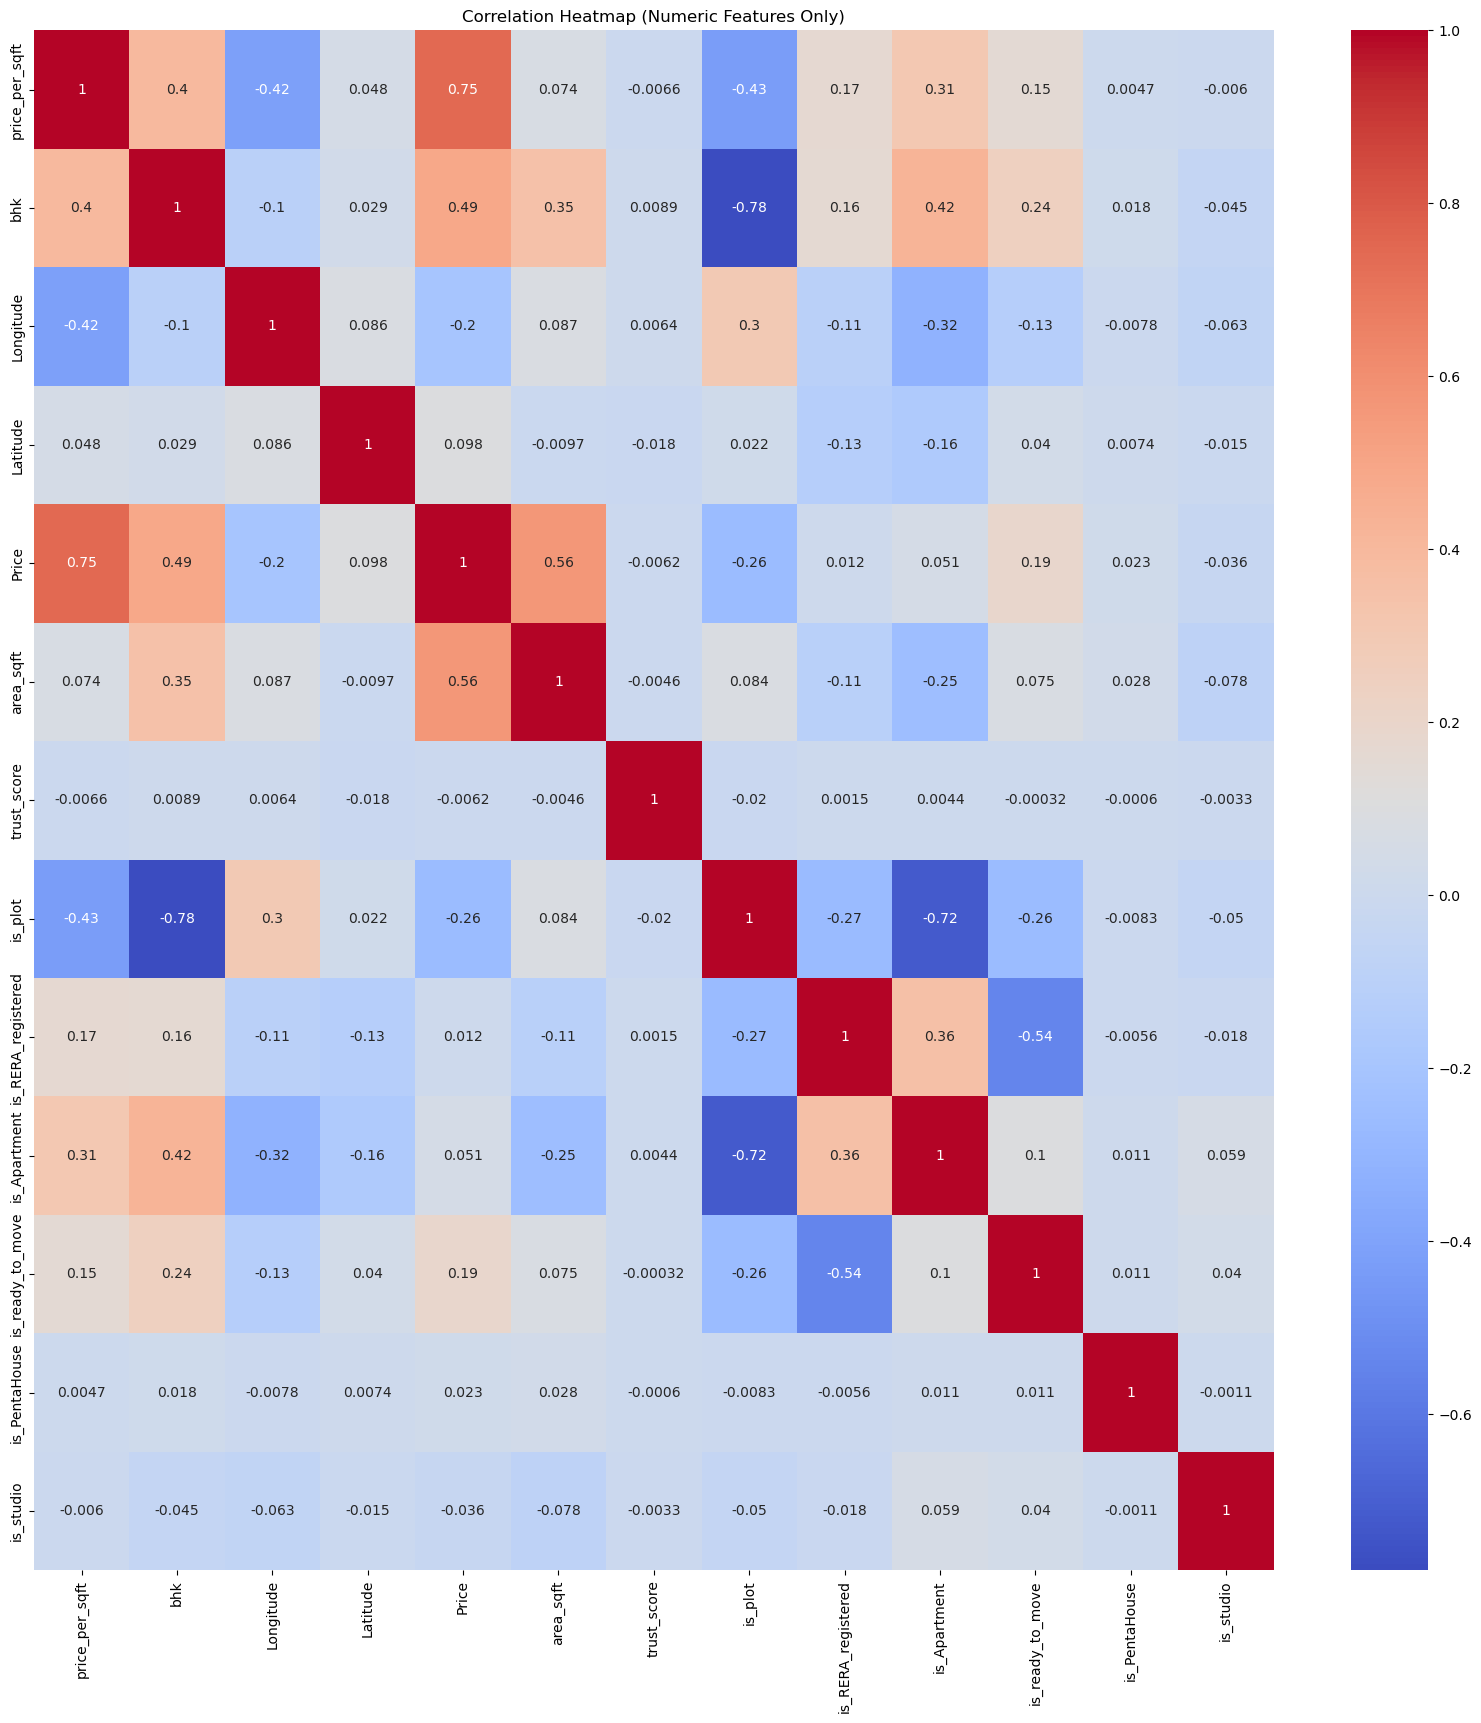

In [19]:
numeric_data = data.select_dtypes(include=['number'])

plt.figure(figsize=(20, 20))
sns.heatmap(numeric_data.corr(), cmap='coolwarm', annot=True)
plt.title("Correlation Heatmap (Numeric Features Only)")
plt.show()

In [20]:
data.head()

,Property_type,price_per_sqft,Property_building_status,city,bhk,locality,Longitude,Latitude,Price,area_sqft,sub_urban,is_furnished,trust_score,is_plot,is_RERA_registered,is_Apartment,is_ready_to_move,is_PentaHouse,is_studio,category
0,Apartment,4285,ACTIVE,Ahmedabad,3,Bopal,72.465103,23.037386,75.0000,1750,Ahmedabad West,Unfurnished,4.0,0,1,1,0,0,0,sell
1,Apartment,7000,ACTIVE,Ahmedabad,4,Ambli,72.479668,23.027061,236.8800,3384,Ahmedabad West,Unfurnished,4.0,0,1,1,0,0,0,sell
2,Apartment,5752,ACTIVE,Ahmedabad,3,Other,72.558502,23.055193,132.0084,2295,Ahmedabad West,Unfurnished,4.0,0,0,1,1,0,0,sell
3,Apartment,2486,ACTIVE,Ahmedabad,2,Changodar,72.454720,22.940430,22.8300,918,Ahmedabad South,Unfurnished,4.0,0,0,1,1,0,0,sell
4,Apartment,5324,ACTIVE,Ahmedabad,3,Shilaj,72.477890,23.043703,93.7100,1760,Ahmedabad West,Unfurnished,4.0,0,1,1,0,0,0,sell


### Data Spiliting

In [21]:
X = data.drop(['Price','price_per_sqft'], axis=1)
y = data['Price']

In [22]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [23]:
print(X_train.dtypes)

Property_type                object
Property_building_status     object
city                         object
bhk                           int64
locality                     object
Longitude                   float64
Latitude                    float64
area_sqft                     int64
sub_urban                    object
is_furnished                 object
trust_score                 float64
is_plot                       int32
is_RERA_registered            int32
is_Apartment                  int32
is_ready_to_move              int32
is_PentaHouse                 int32
is_studio                     int32
category                     object
dtype: object


### Encoding

In [24]:
locality_mean = X_train.join(y_train).groupby('locality')['Price'].mean()
X_train['locality'] = X_train['locality'].map(locality_mean)
X_test['locality'] = X_test['locality'].map(locality_mean)
X_test['locality'] = X_test['locality'].fillna(X_train['locality'].mean())

In [25]:
suburban_mean = X_train.join(y_train).groupby('sub_urban')['Price'].mean()
X_train['sub_urban'] = X_train['sub_urban'].map(suburban_mean)
X_test['sub_urban'] = X_test['sub_urban'].map(suburban_mean)
X_test['sub_urban'] = X_test['sub_urban'].fillna(X_train['sub_urban'].mean())

In [26]:
X_train = X_train.drop(columns=["Locality", "Suburban"], errors="ignore")
X_test = X_test.drop(columns=["Locality", "Suburban"], errors="ignore")

In [27]:
cat_cols = ['Property_type', 'Property_building_status', 'is_furnished', 'category', 'city']
ohe = OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False)

X_train_cat = ohe.fit_transform(X_train[cat_cols])
X_test_cat = ohe.transform(X_test[cat_cols])

ohe_cols = ohe.get_feature_names_out(cat_cols)
X_train_cat = pd.DataFrame(X_train_cat, columns=ohe_cols, index=X_train.index)
X_test_cat = pd.DataFrame(X_test_cat, columns=ohe_cols, index=X_test.index)

X_train = X_train.drop(columns=cat_cols)
X_test = X_test.drop(columns=cat_cols)

X_train = pd.concat([X_train, X_train_cat], axis=1)
X_test = pd.concat([X_test, X_test_cat], axis=1)

In [28]:
X_train.head()

,bhk,locality,Longitude,Latitude,area_sqft,sub_urban,trust_score,is_plot,is_RERA_registered,is_Apartment,...,Property_building_status_UNVERIFIED,is_furnished_Semi-Furnished,is_furnished_Unfurnished,city_Bangalore,city_Chennai,city_Delhi,city_Hyderabad,city_Kolkata,city_Lucknow,city_Mumbai
57334,2,63.642344,80.199348,12.942539,940,81.056965,4.0,0,0,1,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
110044,4,176.781172,77.061066,28.586040,1950,159.744957,4.0,0,0,1,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
43101,3,105.600906,77.697517,12.975423,1582,152.239039,4.0,0,0,1,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
134180,0,23.499612,78.205902,17.071301,1800,33.960136,4.0,1,1,0,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
108616,3,202.283529,77.049995,28.589540,2200,159.744957,4.0,0,0,1,...,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


### Data Scaling

In [29]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

y_train_log = np.log1p(y_train)
y_test_log = np.log1p(y_test)

### Models Selection Using K Fold Validation

In [30]:
lr = LinearRegression()
ridge = Ridge()
lasso = Lasso(max_iter=100000, alpha=0.1)
dt = DecisionTreeRegressor()
rf = RandomForestRegressor()
gb = GradientBoostingRegressor()
xgb = XGBRegressor(n_estimators=200,learning_rate=0.05,random_state=42)
cb = CatBoostRegressor(iterations=500,learning_rate=0.05,verbose=0,random_state=42)
lgbm = LGBMRegressor(n_estimators=500,learning_rate=0.05,verbose=-1,random_state=42)

models = {
    "Linear Regression": lr,
    "Ridge": ridge,
    "Lasso": lasso,
    "Decision Tree": dt,
    "Random Forest": rf,
    "Gradient Boosting": gb,
    "XG Boost": xgb,
    "CatBoost": cb,
    "LightGBM": lgbm,
}

In [31]:
for name, model in models.items():
    if name in ["Linear Regression", "Ridge", "Lasso"]: 
        scores = cross_val_score(model, X_train_scaled, y_train_log, cv=5, scoring='r2')
    else:
        scores = cross_val_score(model, X_train, y_train_log, cv=5, scoring='r2')
    
    print(f"{name} CV R2:", scores.mean())

Linear Regression CV R2: 0.7433829905886788
Ridge CV R2: 0.7433830346471547
Lasso CV R2: 0.7432648933523098
Decision Tree CV R2: 0.8497143524414341
Random Forest CV R2: 0.9078680243840587
Gradient Boosting CV R2: 0.852082037142344
XG Boost CV R2: 0.8912759340125153
CatBoost CV R2: 0.8869605645556102
LightGBM CV R2: 0.9020968437505339


### HyperTunning Parameters

In [ ]:
rf = RandomForestRegressor(
    random_state=42,
    n_jobs=-1
)

param_dist = {
    'n_estimators': [200, 400, 600, 800, 1000],
    'max_depth': [10, 15, 20, 25, 30, None],
    'min_samples_split': [2, 5, 10, 15],
    'min_samples_leaf': [1, 2, 4, 6],
    'max_features': ['sqrt', 'log2', None],
    'bootstrap': [True, False]
}

random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_dist,
    n_iter=10,
    scoring='r2',
    cv=5,
    verbose=2,
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train, y_train_log)

print("Best R2:", random_search.best_score_)
print("Best Params:", random_search.best_params_)

Fitting 5 folds for each of 10 candidates, totalling 50 fits


In [41]:
rf = RandomForestRegressor(
    n_estimators=800,
    max_depth=20,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features='sqrt',
    bootstrap=True,
    n_jobs=-1,
    random_state=42
)

scores = cross_val_score(rf, X_train, y_train_log, cv=5, scoring='r2')
print("CV R2:", scores.mean())

CV R2: 0.9090265694569091


In [33]:
xgb = XGBRegressor(
    random_state=42,
    n_jobs=-1
)

param_dist = {
    'n_estimators': [500, 800, 1000, 1200],
    'learning_rate': [0.01, 0.02, 0.03, 0.05],
    'max_depth': [ 5, 6, 7, 8],
    'subsample': [0.6, 0.7, 0.8, 0.9],
    'colsample_bytree': [0.6, 0.7, 0.8, 0.9],
    'gamma': [0, 0.2, 0.5, 1],
    'reg_alpha': [0, 0.2, 0.5, 1],
    'reg_lambda': [0, 0.2, 0.5, 1]
}

random_search = RandomizedSearchCV(
    estimator=xgb,
    param_distributions=param_dist,
    n_iter=10,      
    scoring='r2',
    cv=5,
    verbose=2,
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train, y_train_log)

print("Best R2:", random_search.best_score_)
print("Best Params:", random_search.best_params_)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best R2: 0.9077895427813509
Best Params: {'subsample': 0.6, 'reg_lambda': 1, 'reg_alpha': 1, 'n_estimators': 1000, 'max_depth': 7, 'learning_rate': 0.05, 'gamma': 0.5, 'colsample_bytree': 0.8}


In [34]:
xgb = XGBRegressor(
    n_estimators= 1000,
    learning_rate=0.05,
    max_depth=7,
    subsample=0.6,
    colsample_bytree=0.8,
    gamma=0.5,
    reg_alpha=1,
    reg_lambda=1,
    n_jobs=-1,
    random_state=42
)
scores = cross_val_score(xgb, X_train, y_train_log, cv=5, scoring='r2')
print("CV R2:", scores.mean())

CV R2: 0.9076850315189097


In [35]:
cb = CatBoostRegressor(
    loss_function='RMSE',
    verbose=0,
    random_state=42
)

param_dist = {
    'iterations': [500, 800, 1000, 1200],
    'learning_rate': [0.01, 0.02, 0.03, 0.05],
    'depth': [ 5, 6, 7, 8],
    'l2_leaf_reg': [ 3, 5, 7, 9],
    'random_strength': [1, 2, 5, 10],
    'bagging_temperature': [0, 1, 2, 3],
    'border_count': [32, 64, 128]
}

random_search = RandomizedSearchCV(
    estimator=cb,
    param_distributions=param_dist,
    n_iter=10,      
    scoring='r2',
    cv=5,
    verbose=2,
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train, y_train_log)

print("Best R2:", random_search.best_score_)
print("Best Params:", random_search.best_params_)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best R2: 0.8950955083011916
Best Params: {'random_strength': 1, 'learning_rate': 0.05, 'l2_leaf_reg': 9, 'iterations': 1000, 'depth': 7, 'border_count': 128, 'bagging_temperature': 3}


In [36]:
cb = CatBoostRegressor(
    iterations=1000,
    learning_rate=0.05,
    depth=7,
    l2_leaf_reg=9,
    random_strength=1,
    bagging_temperature=3,
    border_count=128,
    loss_function='RMSE',
    verbose=0,
    random_state=42
)
scores = cross_val_score(cb, X_train, y_train_log, cv=5, scoring='r2')
print("CV R2:", scores.mean())

CV R2: 0.8950955083011916


In [37]:
lgbm = LGBMRegressor(
    random_state=42,
    n_jobs=-1
)

param_dist = {
    'n_estimators': [500, 800, 1000, 1200],
    'learning_rate': [0.01, 0.02, 0.03, 0.05],
    'max_depth': [ 5, 6, 7, 8],
    'num_leaves': [10, 20, 30, 50],
    'subsample': [0.6, 0.7, 0.8, 0.9],
    'colsample_bytree': [0.6, 0.7, 0.8, 0.9],
    'min_child_samples': [5, 10, 20, 25],
    'reg_alpha': [0, 0.2, 0.5, 1],
    'reg_lambda': [0, 0.2, 0.5, 1]
}

random_search = RandomizedSearchCV(
    estimator=lgbm,
    param_distributions=param_dist,
    n_iter=10, 
    scoring='r2',
    cv=5,
    verbose=2,
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train, y_train_log)

print("Best R2:", random_search.best_score_)
print("Best Params:", random_search.best_params_)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best R2: 0.9014651954734202
Best Params: {'subsample': 0.8, 'reg_lambda': 0.2, 'reg_alpha': 0.5, 'num_leaves': 20, 'n_estimators': 1000, 'min_child_samples': 10, 'max_depth': 6, 'learning_rate': 0.05, 'colsample_bytree': 0.6}


In [40]:
lgbm = LGBMRegressor(
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=7,
    num_leaves=20,
    min_child_samples=10,
    subsample=0.8,
    colsample_bytree=0.6,
    reg_alpha=0.5,
    reg_lambda=0.2,
    n_job=-1,
    random_state=42,
    verbose=-1
)
scores = cross_val_score(lgbm, X_train, y_train_log, cv=5, scoring='r2')
print("CV R2:", scores.mean())

CV R2: 0.9024980253040138


### Training Best Models for testing

In [272]:
rf.fit(X_train,y_train_log)
xgb.fit(X_train,y_train_log)
cb.fit(X_train,y_train_log)
lgbm.fit(X_train,y_train_log)

predictions = {
    "Random Forest": rf.predict(X_test),
    "XG Boost": xgb.predict(X_test),
    "CatBoost": cb.predict(X_test),
    "LightGBM": lgbm.predict(X_test),
}

### Models Evaluation

In [273]:
results = []
for name, y_pred in predictions.items():
    mae = mean_absolute_error(y_test_log, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test_log, y_pred))
    r2 = r2_score(y_test_log, y_pred)  
    results.append([name, mae, rmse, r2])

results_df = pd.DataFrame(results, columns=["Model", "MAE", "RMSE", "R2"])
results_df = results_df.sort_values(by="R2", ascending=False)

print(results_df)

           Model        MAE       RMSE        R2
0  Random Forest  17.411875  52.530905  0.914235
3       LightGBM  23.524076  56.219518  0.901767
1       XG Boost  24.875586  58.895302  0.892194
2       CatBoost  25.608368  59.921774  0.888403


In [ ]:
results_actual = []

for name, y_pred in predictions.items():
    y_pred_actual = np.expm1(y_pred)
    y_test_actual = np.expm1(y_test)
    
    mae = mean_absolute_error(y_test, y_pred_actual)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred_actual))
    r2 = r2_score(y_test, y_pred_actual)
    
    results_actual.append([name, mae, rmse, r2])

results_actual_df = pd.DataFrame(results_actual, columns=["Model", "MAE", "RMSE", "R2"])
results_actual_df = results_df.sort_values(by="R2", ascending=False)

print(results_actual_df)